## 0. Environment Setup (Kaggle Starter Cell)

**What this cell does:** Kaggle's default starter cell. It imports `numpy`/`pandas`, walks `/kaggle/input` to list attached files and imports `kagglehub`.

**Output:** none (the dataset is already attached, so nothing needed downloading).

**Why it matters:** Confirms the notebook runs inside the Kaggle Docker image, where the GPU and the dataset paths used later are available.

In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

# Week 6: Applied Computer Vision in Your Own Domain

**Name:** Haseeb Bilal  
**Course:** Introduction to Applied AI  
**Project:** Project 2 — Deep Learning Applications  
**Dataset:** Intel Image Classification  
**Model:** ResNet-18  
**Task:** Six-class image classification

## 1. Configuration and Path Check

**What this cell does:** Defines the dataset paths and the global settings used by the whole notebook, then checks the folders exist.

| Setting | Value | Meaning |
|---|---|---|
| `IMG_SIZE` | 224 | ResNet-18 input resolution (224 × 224) |
| `BACKBONE` | resnet18 | pretrained feature extractor |
| `GRAYSCALE` | False | keep 3 colour channels (scene colour is informative) |
| `GROUP_PATTERN` | None | no patient/subject ID in Intel filenames, so every file is its own group |
| `TARGET_RECALL` | 0.95 | binary-task setting, **not used** here (six-class task, `POSITIVE = None`) |

**Output recorded:** both folders exist (`True`, `True`).

**By-hand check (input size):** one network input holds $224 \times 224 \times 3 = 150{,}528$ numbers.

In [2]:

import os

DATA_ROOT = "/kaggle/input/datasets/puneet6060/intel-image-classification"

TRAIN_DIR = os.path.join(DATA_ROOT, "seg_train", "seg_train")
TEST_DIR  = os.path.join(DATA_ROOT, "seg_test", "seg_test")

GRAYSCALE = False
IMG_SIZE = 224
BACKBONE = "resnet18"

# Intel scene images ke filenames mein known patient/subject ID pattern nahi.
# Is liye filename ko group banayenge aur limitations explain karenge.
GROUP_PATTERN = None

POSITIVE = None       # Six-class task: binary positive class nahi
TARGET_RECALL = 0.95

print("Training folder exists:", os.path.isdir(TRAIN_DIR))
print("Testing folder exists:", os.path.isdir(TEST_DIR))
print("Training path:", TRAIN_DIR)
print("Testing path:", TEST_DIR)

if not os.path.isdir(TRAIN_DIR) or not os.path.isdir(TEST_DIR):
    raise FileNotFoundError(
        "Path check karo: Kaggle Input panel mein train aur test folders dekho."
    )


Training folder exists: True
Testing folder exists: True
Training path: /kaggle/input/datasets/puneet6060/intel-image-classification/seg_train/seg_train
Testing path: /kaggle/input/datasets/puneet6060/intel-image-classification/seg_test/seg_test


## 2. Imports, Random Seeds and Device

**What this cell does:** Loads PyTorch, torchvision, scikit-learn and plotting tools, fixes the random seeds (`42`) so the split and weight initialisation are reproducible, and selects the GPU.

**Output recorded:** Device = `cuda`, PyTorch `2.11.0+cu128`, Torchvision `0.26.0+cu128`.

**Why it matters:** Fixed seeds mean the same 85/15 split every run. `StratifiedGroupKFold` is imported (for patient-level splitting) but is not needed here because every group has exactly one image (see Section 3).

In [3]:

import re
import time
import copy
import hashlib
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms, models

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("PyTorch version:", torch.__version__)
print("Torchvision version:", __import__("torchvision").__version__)


Device: cuda
PyTorch version: 2.11.0+cu128
Torchvision version: 0.26.0+cu128


## 3. Index the Dataset and Audit Class Balance

**What this cell does:** Walks each class folder and builds a table with one row per image (`path`, `label`, `file`, `group`). Because `GROUP_PATTERN = None`, `group = file`.

**Outputs recorded**

| Class | Train n | Share of train | Test n |
|---|---|---|---|
| buildings | 2,191 | 15.61 % | 437 |
| forest | 2,271 | 16.18 % | 474 |
| glacier | 2,404 | 17.13 % | 553 |
| mountain | 2,512 | 17.90 % | 525 |
| sea | 2,274 | 16.20 % | 510 |
| street | 2,382 | 16.97 % | 501 |
| **Total** | **14,034** | 100 % | **3,000** |

**Hand calculations**

- Training total: $2191 + 2271 + 2404 + 2512 + 2274 + 2382 = 14{,}034$ ✔
- Test total: $437 + 474 + 553 + 525 + 510 + 501 = 3000$ ✔
- Share of a class: $\dfrac{n_c}{N}$, e.g. buildings $= \dfrac{2191}{14034} = 0.1561$
- Imbalance ratio: $\dfrac{n_{\max}}{n_{\min}} = \dfrac{2512}{2191} = 1.1465 \approx 1.147$ ✔ (mild imbalance; a perfectly balanced set would give 1.000)
- Average images per group: $\dfrac{14034}{14034} = 1.00$ ✔ (each file is its own group, so group-aware splitting gives no extra protection here)
- Balanced class weights (the formula from Question 2): $w_c = \dfrac{N}{K\,n_c}$ with $N/K = 14034/6 = 2339$

| Class | $w_c = 2339 / n_c$ |
|---|---|
| buildings | 1.068 |
| forest | 1.030 |
| glacier | 0.973 |
| mountain | 0.931 |
| sea | 1.029 |
| street | 0.982 |

All weights lie between 0.93 and 1.07, which is why the notebook trains with plain `CrossEntropyLoss` and no re-weighting.

In [5]:

def index_folder(folder):
    """One row per image: full path, class label, filename, group."""
    rows = []

    for cls in sorted(os.listdir(folder)):
        class_dir = os.path.join(folder, cls)

        if not os.path.isdir(class_dir):
            continue

        for filename in sorted(os.listdir(class_dir)):
            if filename.lower().endswith(
                (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")
            ):
                rows.append({
                    "path": os.path.join(class_dir, filename),
                    "label": cls,
                    "file": filename
                })

    df = pd.DataFrame(rows)

    if df.empty:
        raise ValueError(f"No images found in {folder}")

    if GROUP_PATTERN:
        matched = df["file"].str.extract(GROUP_PATTERN, expand=False)
        df["group"] = matched.fillna(df["file"])
    else:
        df["group"] = df["file"]

    return df


train_df = index_folder(TRAIN_DIR)
test_df = index_folder(TEST_DIR)

classes = sorted(train_df["label"].unique())
class_to_idx = {name: i for i, name in enumerate(classes)}

print("Classes:", classes)
print("Number of classes:", len(classes))
print("Training images:", len(train_df))
print("Testing images:", len(test_df))

print("\nTraining class counts:")
counts = train_df["label"].value_counts().reindex(classes, fill_value=0)
print(counts)

print("\nTesting class counts:")
print(test_df["label"].value_counts().reindex(classes, fill_value=0))

imbalance_ratio = counts.max() / counts.min()
print("\nImbalance ratio (max/min):", round(imbalance_ratio, 3))
print("Average images per group:", round(len(train_df) / train_df["group"].nunique(), 2))


Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Number of classes: 6
Training images: 14034
Testing images: 3000

Training class counts:
label
buildings    2191
forest       2271
glacier      2404
mountain     2512
sea          2274
street       2382
Name: count, dtype: int64

Testing class counts:
label
buildings    437
forest       474
glacier      553
mountain     525
sea          510
street       501
Name: count, dtype: int64

Imbalance ratio (max/min): 1.147
Average images per group: 1.0


## 4. Image Size, Colour Mode and Visual Inspection

**What this cell does:** Opens a random sample of 300 training images to read their width, height and colour mode, then plots 5 random examples per class (6 rows × 5 columns = 30 axes).

**Outputs recorded:** all 300 images are $150 \times 150$ (std = 0.0), all in `RGB` mode.

**Hand calculations**

- Raw pixel values per image: $150 \times 150 \times 3 = 67{,}500$
- Values after resizing to 224: $224 \times 224 \times 3 = 150{,}528$
- Upscaling factor: $\dfrac{224}{150} = 1.493$ per side, so each side is stretched by about 49 %. Images are **up-sampled**, not down-sampled, so no detail is lost, but they will look soft.
- Zero spread in size means one `Resize((224, 224))` is enough and no cropping or padding is needed.

Image dimensions (sample of up to 300 images):
       width  height
count  300.0   300.0
mean   150.0   150.0
std      0.0     0.0
min    150.0   150.0
25%    150.0   150.0
50%    150.0   150.0
75%    150.0   150.0
max    150.0   150.0

Colour modes:
mode
RGB    300
Name: count, dtype: int64


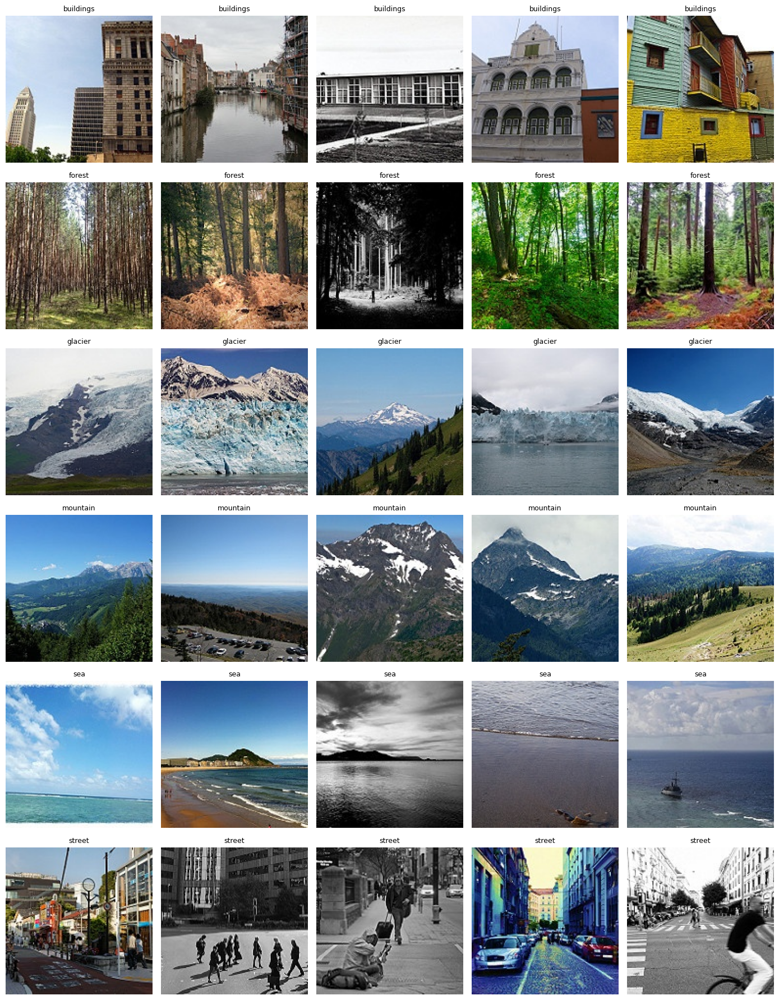

In [6]:

sample = train_df.sample(
    min(300, len(train_df)),
    random_state=42
)

image_info = []

for path in sample["path"]:
    with Image.open(path) as img:
        image_info.append({
            "width": img.size[0],
            "height": img.size[1],
            "mode": img.mode
        })

info_df = pd.DataFrame(image_info)

print("Image dimensions (sample of up to 300 images):")
print(info_df[["width", "height"]].describe().round(1))

print("\nColour modes:")
print(info_df["mode"].value_counts())

fig, axes = plt.subplots(
    len(classes), 5,
    figsize=(14, 3 * len(classes))
)

for row, cls in enumerate(classes):
    paths = train_df.loc[train_df["label"] == cls, "path"]
    paths = paths.sample(min(5, len(paths)), random_state=42).tolist()

    for col in range(5):
        ax = axes[row, col] if len(classes) > 1 else axes[col]

        if col < len(paths):
            img = Image.open(paths[col]).convert("RGB")
            ax.imshow(img)
            ax.set_title(cls, fontsize=9)

        ax.axis("off")

plt.tight_layout()
plt.show()



## Part 1 — Write It: Dataset Audit

**Number of training images:** 14,034

**Number of test images:** 3,000

**Six class counts (training dataset):**
- Buildings: 2,191
- Forest: 2,271
- Glacier: 2,404
- Mountain: 2,512
- Sea: 2,274
- Street: 2,382

**Imbalance ratio (maximum class count / minimum class count):** 1.147

**Typical image dimensions:** 150 × 150 pixels.

**Colour modes observed:** RGB (all 300 sampled images).

**One possible shortcut feature:** Background, lighting, or scene-specific objects, such as buildings in street scenes or trees in forest scenes.

**Why that feature might mislead the model:** The model might rely too heavily on background colours or specific objects instead of learning the overall features of each scene. If these features change in new images, the model may misclassify them.


### Check of the Audit Numbers Above (by hand)

- $2191 + 2271 + 2404 + 2512 + 2274 + 2382 = 14{,}034$ ✔ and imbalance $= 2512/2191 = 1.147$ ✔
- Largest class share $2512/14034 = 17.9\,\%$, smallest $2191/14034 = 15.6\,\%$; ideal balanced share is $1/6 = 16.7\,\%$. The imbalance is mild.
- The audit mentions a **shortcut feature** (background/scene objects). Sections 20 and 24 give a concrete case: confusion between street and buildings (52 errors) and a watermark-driven Grad-CAM map.

## 5. Exact-Duplicate Check (MD5 Hashing)

**What this cell does:** Computes an MD5 hash of every file's bytes (train + test). Two files with the same hash are byte-for-byte identical.

$$\text{duplicate} \iff \text{MD5}(\text{file}_i) = \text{MD5}(\text{file}_j)$$

**Outputs recorded:** 17,034 files hashed ($14{,}034 + 3000 = 17{,}034$ ✔); **36 images** fall in duplicate groups, forming **18 unique hashes**.

**Hand calculations**

- Group size: $\dfrac{36}{18} = 2$, so every duplicate group is a pair.
- Duplicate rate: $\dfrac{36}{17034} = 0.211\,\%$ of all files.
- Of the 15 groups visible in the 30-row preview, 5 pairs have the **same** label (sea/sea, street/street ×2, forest/forest ×2) and 10 pairs have **conflicting** labels (e.g. mountain vs glacier, buildings vs street). Conflicting labels are label noise: the same pixels carry two different answers.

In [9]:

import os
import hashlib
import pandas as pd

def md5_file(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

all_df = pd.concat([
    train_df.assign(split="train"),
    test_df.assign(split="test")
], ignore_index=True)

print("Total images to check:", len(all_df), flush=True)

hashes = []
for i, path in enumerate(all_df["path"]):
    hashes.append(md5_file(path))

    if (i + 1) % 500 == 0:
        print(f"Checked {i + 1}/{len(all_df)} images", flush=True)

all_df["md5"] = hashes

duplicate_rows = all_df[
    all_df.duplicated("md5", keep=False)
].sort_values("md5")

print("\nImages in exact-duplicate groups:", len(duplicate_rows))
print("Unique duplicate hashes:", duplicate_rows["md5"].nunique())

if len(duplicate_rows):
    display(duplicate_rows[["split", "label", "file", "md5"]].head(30))
else:
    print("No exact duplicate files detected.")


Total images to check: 17034
Checked 500/17034 images
Checked 1000/17034 images
Checked 1500/17034 images
Checked 2000/17034 images
Checked 2500/17034 images
Checked 3000/17034 images
Checked 3500/17034 images
Checked 4000/17034 images
Checked 4500/17034 images
Checked 5000/17034 images
Checked 5500/17034 images
Checked 6000/17034 images
Checked 6500/17034 images
Checked 7000/17034 images
Checked 7500/17034 images
Checked 8000/17034 images
Checked 8500/17034 images
Checked 9000/17034 images
Checked 9500/17034 images
Checked 10000/17034 images
Checked 10500/17034 images
Checked 11000/17034 images
Checked 11500/17034 images
Checked 12000/17034 images
Checked 12500/17034 images
Checked 13000/17034 images
Checked 13500/17034 images
Checked 14000/17034 images
Checked 14500/17034 images
Checked 15000/17034 images
Checked 15500/17034 images
Checked 16000/17034 images
Checked 16500/17034 images
Checked 17000/17034 images

Images in exact-duplicate groups: 36
Unique duplicate hashes: 18


,split,label,file,md5
10499,train,sea,19255.jpg,0b425690368e341777a1d5ee3aef3e1e
11400,train,sea,7872.jpg,0b425690368e341777a1d5ee3aef3e1e
7800,train,mountain,16696.jpg,0e1ff2651ce5f2b2b435adc3704f5da8
6643,train,glacier,8191.jpg,0e1ff2651ce5f2b2b435adc3704f5da8
16677,test,street,21170.jpg,25ea15ceafd51672152b5494d82678e0
1573,train,buildings,4634.jpg,25ea15ceafd51672152b5494d82678e0
11197,train,sea,6337.jpg,2ae38911a2006f58fe5aa8e3d3a8cf99
8971,train,mountain,7037.jpg,2ae38911a2006f58fe5aa8e3d3a8cf99
12711,train,street,17693.jpg,336ff282d3c3e4321e1a1629140a8548
13733,train,street,7618.jpg,336ff282d3c3e4321e1a1629140a8548


## 6. Near-Duplicate Screening (First Pass: 50 Test vs 500 Train)

**What this cell does:** Shrinks each image to a $16 \times 16$ grey thumbnail, z-scores it and measures the mean absolute difference between a test thumbnail and every sampled training thumbnail.

$$\tilde a_i = \frac{a_i - \bar a}{s_a + 10^{-6}}, \qquad d(x,y) = \frac{1}{256}\sum_{i=1}^{256} |\tilde x_i - \tilde y_i|$$

A test image is flagged if its nearest training distance is below the threshold $0.10$.

**Outputs recorded:** 50 test images vs 500 train images; **0** candidates; smallest distance in the table = 0.257.

**Hand calculations**

- Comparisons made: $50 \times 500 = 25{,}000$ thumbnail pairs.
- Feature length: $16 \times 16 = 256$ values per thumbnail.
- Reference scale: for two unrelated z-scored images, each difference is roughly $N(0,\,2)$, so $E|\tilde x - \tilde y| \approx \dfrac{2}{\sqrt{\pi}} = 1.128$. The closest observed pair (0.257) is only 23 % of that random level, but still 2.6 times the 0.10 flag threshold ($0.257 / 0.10 = 2.57$), so none is flagged.
- Limitation: only $500 / 14034 = 3.6\,\%$ of training images were searched.

In [10]:

def fingerprint(path, size=16):
    with Image.open(path) as img:
        arr = np.asarray(
            img.convert("L").resize((size, size)),
            dtype=np.float32
        )

    return ((arr - arr.mean()) / (arr.std() + 1e-6)).flatten()


train_sample = train_df.sample(
    min(500, len(train_df)), random_state=42
).reset_index(drop=True)

test_sample = test_df.sample(
    min(50, len(test_df)), random_state=42
).reset_index(drop=True)

print("Creating fingerprints...", flush=True)

train_fp = np.stack([fingerprint(p) for p in train_sample["path"]])
test_fp = np.stack([fingerprint(p) for p in test_sample["path"]])

nearest_distances = []

for i, test_vector in enumerate(test_fp):
    distances = np.abs(train_fp - test_vector).mean(axis=1)
    nearest_distances.append(distances.min())

    if (i + 1) % 10 == 0:
        print(f"Compared {i + 1}/{len(test_fp)} test images", flush=True)

nearest_distances = np.asarray(nearest_distances)
threshold = 0.10

print("\nTest sample checked:", len(test_sample))
print("Training sample compared:", len(train_sample))
print("Possible near-duplicate candidates:",
      int((nearest_distances < threshold).sum()))

display(
    test_sample.assign(
        nearest_distance=nearest_distances,
        possible_candidate=nearest_distances < threshold
    ).sort_values("nearest_distance").head(10)
)


Creating fingerprints...
Compared 10/50 test images
Compared 20/50 test images
Compared 30/50 test images
Compared 40/50 test images
Compared 50/50 test images

Test sample checked: 50
Training sample compared: 500
Possible near-duplicate candidates: 0


,path,label,file,group,nearest_distance,possible_candidate
37,/kaggle/input/datasets/puneet6060/intel-image-...,buildings,23143.jpg,23143.jpg,0.257391,False
40,/kaggle/input/datasets/puneet6060/intel-image-...,buildings,21923.jpg,21923.jpg,0.323395,False
3,/kaggle/input/datasets/puneet6060/intel-image-...,buildings,22415.jpg,22415.jpg,0.328061,False
21,/kaggle/input/datasets/puneet6060/intel-image-...,buildings,22810.jpg,22810.jpg,0.347371,False
15,/kaggle/input/datasets/puneet6060/intel-image-...,forest,24234.jpg,24234.jpg,0.357730,False
30,/kaggle/input/datasets/puneet6060/intel-image-...,glacier,20810.jpg,20810.jpg,0.381932,False
2,/kaggle/input/datasets/puneet6060/intel-image-...,mountain,22804.jpg,22804.jpg,0.386689,False
9,/kaggle/input/datasets/puneet6060/intel-image-...,street,20652.jpg,20652.jpg,0.393845,False
44,/kaggle/input/datasets/puneet6060/intel-image-...,mountain,21076.jpg,21076.jpg,0.411993,False
5,/kaggle/input/datasets/puneet6060/intel-image-...,glacier,21657.jpg,21657.jpg,0.415638,False


## 7. Do Exact Duplicates Cross the Train/Test Boundary?

**What this cell does:** For each duplicate hash it checks whether the group contains both a `train` and a `test` file. This is **data leakage**: the model could be "tested" on an image it has already seen.

**Outputs recorded:** **3** hashes are shared across train and test:

| Test file | Test label | Train file | Train label |
|---|---|---|---|
| 21170.jpg | street | 4634.jpg | buildings |
| 21469.jpg | glacier | 14341.jpg | mountain |
| 20805.jpg | buildings | 10408.jpg | street |

**Hand calculations**

- Leaked test images: $3$ out of $3000$, i.e. $\dfrac{3}{3000} = 0.10\,\%$.
- Worst-case effect on accuracy: at most $0.10\,\%$ (3 images). Since the labels in all 3 pairs **disagree**, a memorising model would actually get these 3 wrong, so the effect is tiny and does not inflate the reported score.
- Conclusion: leakage is negligible, but it is worth reporting honestly (and the conflicting labels show the dataset is slightly noisy).

In [11]:

if len(duplicate_rows):
    split_sets = (
        duplicate_rows.groupby("md5")["split"]
        .agg(lambda s: set(s))
    )

    cross_split_hashes = [
        h for h, split_set in split_sets.items()
        if "train" in split_set and "test" in split_set
    ]

    print("Exact-duplicate hashes shared across train and test:",
          len(cross_split_hashes))

    if cross_split_hashes:
        display(
            duplicate_rows[
                duplicate_rows["md5"].isin(cross_split_hashes)
            ][["split", "label", "file", "path"]].head(30)
        )
else:
    cross_split_hashes = []
    print("Cross-split exact duplicates: 0")


Exact-duplicate hashes shared across train and test: 3


,split,label,file,path
16677,test,street,21170.jpg,/kaggle/input/datasets/puneet6060/intel-image-...
1573,train,buildings,4634.jpg,/kaggle/input/datasets/puneet6060/intel-image-...
7460,train,mountain,14341.jpg,/kaggle/input/datasets/puneet6060/intel-image-...
15126,test,glacier,21469.jpg,/kaggle/input/datasets/puneet6060/intel-image-...
14119,test,buildings,20805.jpg,/kaggle/input/datasets/puneet6060/intel-image-...
11717,train,street,10408.jpg,/kaggle/input/datasets/puneet6060/intel-image-...


## 8. Near-Duplicate Screening (Second Pass: 200 Test vs 2,500 Train)

**What this cell does:** Repeats Section 6 with a larger sample and processes the test images in batches of 10 using broadcasting (`batch[:, None, :] - train_fp[None, :, :]`).

**Outputs recorded:** 200 test images vs 2,500 train images; **0** near-duplicate candidates; five closest distances: $0.152,\ 0.173,\ 0.192,\ 0.197,\ 0.200$.

**Hand calculations**

- Pairs compared: $200 \times 2500 = 500{,}000$ (20 times more than Section 6).
- Coverage: test $\dfrac{200}{3000} = 6.7\,\%$; train $\dfrac{2500}{14034} = 17.8\,\%$.
- The minimum distance fell from $0.257$ to $0.152$ because a larger pool contains closer matches: $\dfrac{0.152}{0.10} = 1.52$ times the flag threshold, still above it.
- A true near-duplicate pair in the full data would only be present in the sampled pool with probability about $0.178$, so **zero flags do not prove the dataset is clean**. This is the caveat the notebook states in its final summary.

In [12]:

def fingerprint(path, size=16):
    """Standardized small grayscale thumbnail for similarity checking."""
    with Image.open(path) as img:
        arr = np.asarray(
            img.convert("L").resize((size, size)),
            dtype=np.float32
        )

    arr = (arr - arr.mean()) / (arr.std() + 1e-6)
    return arr.flatten()


# Limit computation so the notebook does not take excessively long.
train_sample = train_df.sample(
    min(2500, len(train_df)), random_state=42
).reset_index(drop=True)

test_sample = test_df.sample(
    min(200, len(test_df)), random_state=42
).reset_index(drop=True)

print("Building fingerprints...")
train_fp = np.stack([fingerprint(p) for p in train_sample["path"]])
test_fp = np.stack([fingerprint(p) for p in test_sample["path"]])

nearest_distances = []

# Compare test fingerprints in small batches against sampled training fingerprints.
for start in range(0, len(test_fp), 10):
    batch = test_fp[start:start + 10]

    distances = np.abs(
        batch[:, None, :] - train_fp[None, :, :]
    ).mean(axis=2)

    nearest_distances.extend(distances.min(axis=1))

nearest_distances = np.asarray(nearest_distances)

# This is a screening threshold, not proof that two images are duplicates.
near_threshold = 0.10
near_flags = nearest_distances < near_threshold

print("Test sample size:", len(test_sample))
print("Training comparison sample size:", len(train_sample))
print("Sampled test images with a near-duplicate candidate:",
      int(near_flags.sum()))
print("Five closest distances:",
      np.sort(nearest_distances)[:5].round(3))

near_results = test_sample.copy()
near_results["nearest_distance"] = nearest_distances
near_results["possible_near_duplicate"] = near_flags

display(
    near_results.sort_values("nearest_distance").head(10)[
        ["label", "file", "nearest_distance", "possible_near_duplicate", "path"]
    ]
)


Building fingerprints...
Test sample size: 200
Training comparison sample size: 2500
Sampled test images with a near-duplicate candidate: 0
Five closest distances: [0.152 0.173 0.192 0.197 0.2  ]


,label,file,nearest_distance,possible_near_duplicate,path
103,mountain,21280.jpg,0.152155,False,/kaggle/input/datasets/puneet6060/intel-image-...
106,mountain,24166.jpg,0.172959,False,/kaggle/input/datasets/puneet6060/intel-image-...
73,mountain,23702.jpg,0.191648,False,/kaggle/input/datasets/puneet6060/intel-image-...
81,mountain,22884.jpg,0.197306,False,/kaggle/input/datasets/puneet6060/intel-image-...
137,mountain,22391.jpg,0.199989,False,/kaggle/input/datasets/puneet6060/intel-image-...
192,mountain,24169.jpg,0.206373,False,/kaggle/input/datasets/puneet6060/intel-image-...
105,forest,23879.jpg,0.222684,False,/kaggle/input/datasets/puneet6060/intel-image-...
164,mountain,22306.jpg,0.251863,False,/kaggle/input/datasets/puneet6060/intel-image-...
37,buildings,23143.jpg,0.257391,False,/kaggle/input/datasets/puneet6060/intel-image-...
184,buildings,21243.jpg,0.264765,False,/kaggle/input/datasets/puneet6060/intel-image-...


## 6. Data Preparation and Transfer Learning

The Intel Image Classification dataset contains six scene categories: buildings, forest, glacier, mountain, sea, and street. In this stage, the data is divided into training and validation subsets. The original test dataset is retained for final evaluation. Images are resized and normalized for the ResNet-18 architecture.

## 9. Stratified Train / Validation Split (85 / 15)

**What this cell does:** Splits the 14,034 labelled images into training and validation sets with `stratify=label`, so each class keeps the same proportion in both. The 3,000 official test images are untouched.

**Hand calculations**

- Validation size: $0.15 \times 14034 = 2105.1 \to$ scikit-learn rounds up $= 2106$ ✔
- Training size: $14034 - 2106 = 11{,}928$ ✔
- Stratified validation count per class $\approx 0.15\,n_c$:

| Class | $0.15\,n_c$ | Validation (output) | Training (output) | Sum |
|---|---|---|---|---|
| buildings | 328.7 | 329 | 1,862 | 2,191 ✔ |
| forest | 340.7 | 341 | 1,930 | 2,271 ✔ |
| glacier | 360.6 | 361 | 2,043 | 2,404 ✔ |
| mountain | 376.8 | 377 | 2,135 | 2,512 ✔ |
| sea | 341.1 | 341 | 1,933 | 2,274 ✔ |
| street | 357.3 | 357 | 2,025 | 2,382 ✔ |

- Class share is preserved: buildings $\dfrac{329}{2106} = 15.62\,\%$ in validation versus $15.61\,\%$ in the full set.

In [13]:
from sklearn.model_selection import train_test_split

train_part, val_part = train_test_split(
    train_df,
    test_size=0.15,
    random_state=42,
    stratify=train_df["label"]
)

train_part = train_part.reset_index(drop=True)
val_part = val_part.reset_index(drop=True)
test_part = test_df.reset_index(drop=True)

print("Training images:", len(train_part))
print("Validation images:", len(val_part))
print("Testing images:", len(test_part))

print("\nTraining class counts:")
print(train_part["label"].value_counts().reindex(classes))

print("\nValidation class counts:")
print(val_part["label"].value_counts().reindex(classes))

Training images: 11928
Validation images: 2106
Testing images: 3000

Training class counts:
label
buildings    1862
forest       1930
glacier      2043
mountain     2135
sea          1933
street       2025
Name: count, dtype: int64

Validation class counts:
label
buildings    329
forest       341
glacier      361
mountain     377
sea          341
street       357
Name: count, dtype: int64


## 10. Image Transformations (Resize, Augmentation, Normalisation)

**What this cell does:** Builds two pipelines. *Training:* resize, random flip, random rotation, colour jitter, tensor conversion, normalisation. *Evaluation:* resize, tensor conversion and normalisation only (no randomness, so scores are reproducible).

**Normalisation equation** (per channel, ImageNet statistics, because the backbone was pretrained on ImageNet):

$$x' = \frac{x - \mu}{\sigma}, \quad \mu = (0.485,\,0.456,\,0.406), \quad \sigma = (0.229,\,0.224,\,0.225)$$

**Hand calculations (red channel, $\mu = 0.485$, $\sigma = 0.229$)**

- Mid-grey pixel $x = 0.5$: $\dfrac{0.5 - 0.485}{0.229} = 0.066$
- White pixel $x = 1.0$: $\dfrac{1.0 - 0.485}{0.229} = 2.249$
- Black pixel $x = 0$: $\dfrac{0 - 0.485}{0.229} = -2.118$
- Blue channel white pixel: $\dfrac{1 - 0.406}{0.225} = 2.640$

**Augmentation ranges:** horizontal flip with $p = 0.5$; rotation in $[-10^\circ, +10^\circ]$; brightness factor in $[0.85,\,1.15]$; contrast factor in $[0.85,\,1.15]$; saturation factor in $[0.90,\,1.10]$. These are mild, so scene identity is not changed (a flipped forest is still a forest).

In [14]:
IMG_SIZE = 224
BATCH_SIZE = 32

imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.10
    ),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])

print("Image transformations created successfully.")

Image transformations created successfully.


## 11. PyTorch Dataset Class

**What this cell does:** `IntelSceneDataset` reads one image on demand (`__getitem__`), converts it to RGB, applies the transform and returns `(image_tensor, label_index)`. `class_to_idx` maps `buildings → 0, forest → 1, glacier → 2, mountain → 3, sea → 4, street → 5`.

**Outputs recorded:** train = 11,928, validation = 2,106, test = 3,000.

**Hand check:** $11{,}928 + 2106 + 3000 = 17{,}034$, the same total as the MD5 audit in Section 5 ✔. Only the training dataset uses the random augmentation pipeline.

In [15]:
class IntelSceneDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        with Image.open(row["path"]) as img:
            image = img.convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = class_to_idx[row["label"]]
        return image, label


train_dataset = IntelSceneDataset(train_part, train_transform)
val_dataset = IntelSceneDataset(val_part, eval_transform)
test_dataset = IntelSceneDataset(test_part, eval_transform)

print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

Train dataset: 11928
Validation dataset: 2106
Test dataset: 3000


## 12. DataLoaders and Batch Shape

**What this cell does:** Wraps each dataset in a `DataLoader` (batch size 32, shuffling only for training, 2 workers on GPU) and fetches one training batch to check shapes.

**Outputs recorded:** image batch `[32, 3, 224, 224]`, label batch `[32]`.

**Hand calculations**

- Values per batch: $32 \times 3 \times 224 \times 224 = 4{,}816{,}896$; in 32-bit floats that is $4{,}816{,}896 \times 4 = 19.27$ MB.
- Iterations per epoch $= \lceil N / 32 \rceil$:
  - Train: $\lceil 11928/32 \rceil = \lceil 372.75 \rceil = 373$ (372 full batches + one of $11928 - 372 \times 32 = 24$ images)
  - Validation: $\lceil 2106/32 \rceil = \lceil 65.8 \rceil = 66$ (last batch 26 images)
  - Test: $\lceil 3000/32 \rceil = \lceil 93.75 \rceil = 94$ (last batch 24 images)

In [16]:
NUM_WORKERS = 2 if device.type == "cuda" else 0

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Device:", device)

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Device: cuda


## 13. Load Pretrained ResNet-18 and Replace the Classifier Head

**What this cell does:** Downloads ImageNet-pretrained ResNet-18 weights (44.7 MB) and replaces the final fully connected layer (`1000` outputs) with a new one that has `6` outputs, then moves the model to the GPU.

**Outputs recorded:** weights loaded, 6 output classes, model on `cuda:0`.

**Hand calculations (parameters in the classifier head)** with 512 input features:

$$\text{params} = 512 \times K + K$$

- Original head: $512 \times 1000 + 1000 = 513{,}000$
- New head: $512 \times 6 + 6 = 3078$
- Total parameters: ResNet-18 has $11{,}689{,}512$, so now $11{,}689{,}512 - 513{,}000 + 3078 = 11{,}179{,}590$.
- The new head is only $\dfrac{3078}{11{,}179{,}590} = 0.028\,\%$ of the model, which is randomly initialised; the other 99.97 % starts from ImageNet knowledge. This is why transfer learning reaches high accuracy in so few epochs.
- Memory check: $11{,}179{,}590 \times 4 \text{ bytes} \approx 44.7$ MB (consistent with the saved model size).

In [17]:
try:
    weights = models.ResNet18_Weights.DEFAULT
    model = models.resnet18(weights=weights)
    print("Pretrained ImageNet weights loaded.")
except Exception as e:
    print("Could not load pretrained weights:", repr(e))
    raise RuntimeError(
        "Pretrained weights are required for this transfer-learning experiment. "
        "Enable internet or provide cached weights in Kaggle, then rerun this cell."
    )

model.fc = nn.Linear(model.fc.in_features, len(classes))
model = model.to(device)

print("Architecture: ResNet-18")
print("Number of output classes:", model.fc.out_features)
print("Model device:", next(model.parameters()).device)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 222MB/s]

Pretrained ImageNet weights loaded.
Architecture: ResNet-18
Number of output classes: 6
Model device: cuda:0


## 14. Loss Function, Optimiser and Learning-Rate Scheduler

**What this cell does:** Sets cross-entropy loss, the Adam optimiser (`lr = 1e-4`, weight decay `1e-4`), a plateau scheduler on validation macro-F1, a maximum of 5 epochs and an early-stopping patience of 2.

**Equations**

$$\text{CE} = -\sum_{c=1}^{K} y_c \log p_c = -\log p_{\text{true}}, \qquad p_c = \frac{e^{z_c}}{\sum_j e^{z_j}}$$

$$\theta_{t+1} = \theta_t - \eta\,\frac{\hat m_t}{\sqrt{\hat v_t} + \epsilon}$$

**Hand calculations**

- Loss of an untrained 6-class guesser (all $p_c = 1/6$): $-\ln(1/6) = \ln 6 = 1.792$. The first-epoch training loss (0.3189) is far below this because the backbone is pretrained.
- Scheduler rule (`mode="max"`, `factor=0.5`, `patience=1`): the learning rate is halved only after the metric fails to improve for **more than 1** epoch, giving $\eta_{new} = 0.5 \times 10^{-4} = 5 \times 10^{-5}$ (see Section 16 for when this triggered).
- Early stopping: training halts when `epochs_without_improvement` $\ge 2$.

In [18]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0001,
    weight_decay=0.0001
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=1
)

EPOCHS = 5
PATIENCE = 2

print("Loss: CrossEntropyLoss")
print("Optimizer: Adam")
print("Initial learning rate:", 0.0001)
print("Maximum epochs:", EPOCHS)

Loss: CrossEntropyLoss
Optimizer: Adam
Initial learning rate: 0.0001
Maximum epochs: 5


## 15. One-Epoch Training / Evaluation Function

**What this cell does:** `run_epoch` runs one pass over a loader. With an optimiser it trains (gradients on); without one it only evaluates. It returns the average loss, accuracy and macro-F1.

**Equations**

$$\text{Loss} = \frac{\sum_{b} \ell_b\, n_b}{N}, \qquad \text{Accuracy} = \frac{\text{correct}}{N}, \qquad \text{Macro-F1} = \frac{1}{K}\sum_{c=1}^{K} F1_c$$

$$F1_c = \frac{2PR}{P+R} = \frac{2\,TP_c}{2\,TP_c + FP_c + FN_c}$$

**Why the loss is multiplied by batch size $n_b$:** the last batch is smaller (24 of 32 images in training), so a plain mean of batch losses would over-weight it. Weighting by $n_b$ gives the exact per-image average.

**Hand example (epoch 1 training):** accuracy $0.8886 \times 11928 = 10{,}599$ images correct (out of 11,928). Total accumulated loss $= 0.3189 \times 11928 = 3803.8$.

In [20]:
def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None

    if training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    total_correct = 0
    total_items = 0

    all_labels = []
    all_preds = []

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            outputs = model(images)
            loss = criterion(outputs, labels)

            if training:
                loss.backward()
                optimizer.step()

        predictions = outputs.argmax(dim=1)

        total_loss += loss.item() * labels.size(0)
        total_correct += (predictions == labels).sum().item()
        total_items += labels.size(0)

        all_labels.extend(labels.detach().cpu().numpy())
        all_preds.extend(predictions.detach().cpu().numpy())

    avg_loss = total_loss / total_items
    accuracy = total_correct / total_items
    macro_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro",
        zero_division=0
    )

    return avg_loss, accuracy, macro_f1

## 16. Training Loop with Early Stopping and Best-Model Saving

**What this cell does:** Trains up to 5 epochs, evaluates on the validation set each epoch, saves the checkpoint with the best validation macro-F1 and stops early if there is no improvement for 2 epochs.

**Outputs recorded**

| Epoch | Train loss | Train acc | Train F1 | Val loss | Val acc | Val F1 | Time |
|---|---|---|---|---|---|---|---|
| 1 | 0.3189 | 0.8886 | 0.8899 | 0.1967 | 0.9335 | **0.9343** (saved) | 42.4 s |
| 2 | 0.1963 | 0.9290 | 0.9300 | 0.2269 | 0.9236 | 0.9250 | 40.8 s |
| 3 | 0.1528 | 0.9454 | 0.9463 | 0.2048 | 0.9292 | 0.9303 | 41.3 s |

**Hand calculations**

- Correct images: validation epoch 1 $= 0.9335 \times 2106 = 1966$ ($1966/2106 = 0.9335$ ✔); epoch 2 $= 1945$; epoch 3 $= 1957$. Training epoch 3 $= 0.9454 \times 11928 = 11{,}277$ correct, i.e. 651 wrong.
- Early-stopping logic: epoch 2 ($0.9250 < 0.9343$) gives 1 epoch without improvement; epoch 3 ($0.9303 < 0.9343$) gives 2, and $2 \ge \text{PATIENCE} = 2$, so training stops after **3 of 5 epochs**.
- Scheduler logic: bad epochs after epoch 3 $= 2 > \text{patience} = 1$, so the learning rate would be halved to $5 \times 10^{-5}$, but training had already ended.
- Best model = epoch 1 weights, with validation macro-F1 $= 0.9343$.
- Timing: total $42.4 + 40.8 + 41.3 = 124.5$ s, an average of $124.5/3 = 41.5$ s per epoch.
- Over-fitting signal: from epoch 1 to 3 training accuracy rose $0.8886 \to 0.9454$ ($+5.68$ points) while validation accuracy slipped $0.9335 \to 0.9292$ ($-0.43$ points).

In [21]:
history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": [],
    "train_macro_f1": [],
    "val_macro_f1": []
}

best_val_f1 = -1.0
best_state = copy.deepcopy(model.state_dict())
epochs_without_improvement = 0

for epoch in range(EPOCHS):
    start_time = time.time()

    train_loss, train_acc, train_f1 = run_epoch(
        model, train_loader, criterion, optimizer
    )

    val_loss, val_acc, val_f1 = run_epoch(
        model, val_loader, criterion
    )

    scheduler.step(val_f1)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_acc)
    history["val_accuracy"].append(val_acc)
    history["train_macro_f1"].append(train_f1)
    history["val_macro_f1"].append(val_f1)

    elapsed = time.time() - start_time

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Train Macro-F1: {train_f1:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val Macro-F1: {val_f1:.4f} | "
        f"Time: {elapsed:.1f}s",
        flush=True
    )

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0

        torch.save(
            best_state,
            "/kaggle/working/best_resnet18.pth"
        )
        print("Best model saved.", flush=True)
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping triggered.")
        break

model.load_state_dict(best_state)

print("\nBest validation Macro-F1:", round(best_val_f1, 4))

Epoch 1/5 | Train Loss: 0.3189 | Train Acc: 0.8886 | Train Macro-F1: 0.8899 | Val Loss: 0.1967 | Val Acc: 0.9335 | Val Macro-F1: 0.9343 | Time: 42.4s
Best model saved.
Epoch 2/5 | Train Loss: 0.1963 | Train Acc: 0.9290 | Train Macro-F1: 0.9300 | Val Loss: 0.2269 | Val Acc: 0.9236 | Val Macro-F1: 0.9250 | Time: 40.8s
Epoch 3/5 | Train Loss: 0.1528 | Train Acc: 0.9454 | Train Macro-F1: 0.9463 | Val Loss: 0.2048 | Val Acc: 0.9292 | Val Macro-F1: 0.9303 | Time: 41.3s
Early stopping triggered.

Best validation Macro-F1: 0.9343


## 17. Learning Curves (Loss, Accuracy, Macro-F1)

**What this cell does:** Plots training vs validation loss, accuracy and macro-F1 for each completed epoch.

**How to read the output with numbers**

- Training loss fell steadily: $\dfrac{0.3189 - 0.1528}{0.3189} = 52.1\,\%$ reduction in 3 epochs.
- Validation loss was best at epoch 1 (0.1967), rose to 0.2269 at epoch 2 ($+15.4\,\%$, since $\dfrac{0.2269 - 0.1967}{0.1967} = 0.154$) and recovered slightly to 0.2048.
- Generalisation gap at epoch 3: accuracy $0.9454 - 0.9292 = 0.0162$ (1.6 points); loss $0.2048 - 0.1528 = 0.0520$.
- Diverging train and validation curves after epoch 1 are the first sign of over-fitting, which is why validation macro-F1 (not training score) selects the checkpoint.

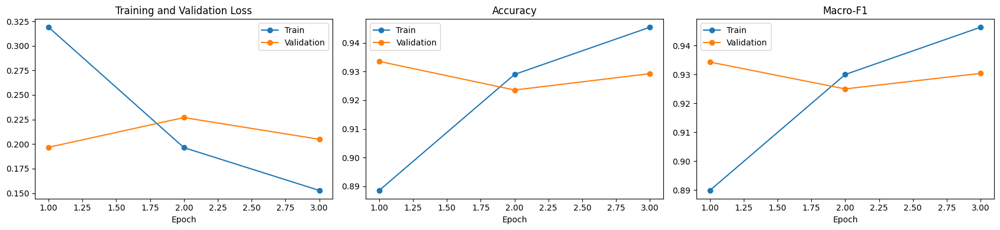

In [22]:
epochs_completed = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 3, figsize=(17, 4))

axes[0].plot(epochs_completed, history["train_loss"], marker="o", label="Train")
axes[0].plot(epochs_completed, history["val_loss"], marker="o", label="Validation")
axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(epochs_completed, history["train_accuracy"], marker="o", label="Train")
axes[1].plot(epochs_completed, history["val_accuracy"], marker="o", label="Validation")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()

axes[2].plot(epochs_completed, history["train_macro_f1"], marker="o", label="Train")
axes[2].plot(epochs_completed, history["val_macro_f1"], marker="o", label="Validation")
axes[2].set_title("Macro-F1")
axes[2].set_xlabel("Epoch")
axes[2].legend()

plt.tight_layout()
plt.show()

## 8. Test Evaluation

The best model checkpoint is evaluated on the held-out test dataset. Accuracy measures overall correctness, while macro-F1 measures performance across classes with equal class weighting. The classification report and confusion matrix identify class-specific strengths and errors.

## 18. Predictions on the Test Set and Headline Metrics

**What this cell does:** Runs the best checkpoint on all 3,000 test images (no gradients), stores the true labels, predicted labels and softmax probabilities, and computes accuracy, macro-F1 and weighted-F1.

**Equations**

$$\text{Accuracy} = \frac{TP_{\text{all}}}{N}, \qquad \text{Macro-F1} = \frac{1}{6}\sum_c F1_c, \qquad \text{Weighted-F1} = \frac{\sum_c n_c\,F1_c}{N}$$

**Outputs recorded:** Accuracy $= 0.9283$, Macro-F1 $= 0.9296$, Weighted-F1 $= 0.9280$.

**Hand calculations** (per-class F1 values come from the next cell)

- Accuracy: $\dfrac{2785}{3000} = 0.9283$ (2785 correct, 215 wrong).
- Macro-F1: $\dfrac{0.9284 + 0.9851 + 0.8793 + 0.8874 + 0.9578 + 0.9395}{6} = \dfrac{5.5775}{6} = 0.9296$ ✔
- Weighted-F1: $\dfrac{437(0.9284) + 474(0.9851) + 553(0.8793) + 525(0.8874) + 510(0.9578) + 501(0.9395)}{3000} = \dfrac{2783.96}{3000} = 0.9280$ ✔
- Macro and weighted are within $0.0016$ of each other because the classes are nearly balanced (ratio 1.147).
- Test macro-F1 is $0.9343 - 0.9296 = 0.0047$ lower than the best validation macro-F1, a small, expected drop.

In [23]:
model.eval()

y_true = []
y_pred = []
y_prob = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        probabilities = torch.softmax(outputs, dim=1)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.numpy())
        y_pred.extend(predictions.cpu().numpy())
        y_prob.extend(probabilities.cpu().numpy())

y_true = np.asarray(y_true)
y_pred = np.asarray(y_pred)
y_prob = np.asarray(y_prob)

test_accuracy = float((y_true == y_pred).mean())

test_macro_f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

test_weighted_f1 = f1_score(
    y_true, y_pred, average="weighted", zero_division=0
)

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Macro-F1: {test_macro_f1:.4f}")
print(f"Test Weighted-F1: {test_weighted_f1:.4f}")

Test Accuracy: 0.9283
Test Macro-F1: 0.9296
Test Weighted-F1: 0.9280


## 19. Per-Class Classification Report

**What this cell does:** Prints precision, recall, F1 and support for every class.

**Equations**

$$P_c = \frac{TP_c}{TP_c + FP_c}, \qquad R_c = \frac{TP_c}{TP_c + FN_c}, \qquad F1_c = \frac{2\,TP_c}{2\,TP_c + FP_c + FN_c}$$

**Recovering the counts from the report** ($TP = R \times \text{support}$, predicted $= TP / P$):

| Class | Support | $TP$ | Predicted | $FP$ | $FN$ | F1 check |
|---|---|---|---|---|---|---|
| buildings | 437 | 402 | 429 | 27 | 35 | $\dfrac{804}{804+27+35} = 0.9284$ |
| forest | 474 | 464 | 468 | 4 | 10 | $\dfrac{928}{928+4+10} = 0.9851$ |
| glacier | 553 | 470 | 516 | 46 | 83 | $\dfrac{940}{940+46+83} = 0.8793$ |
| mountain | 525 | 469 | 532 | 63 | 56 | $\dfrac{938}{938+63+56} = 0.8874$ |
| sea | 510 | 499 | 532 | 33 | 11 | $\dfrac{998}{998+33+11} = 0.9578$ |
| street | 501 | 481 | 523 | 42 | 20 | $\dfrac{962}{962+42+20} = 0.9395$ |
| **Total** | 3000 | **2785** | 3000 | **215** | **215** | |

(Total $FP$ = total $FN$ = 215 because every error is one class's false negative and another class's false positive.)

**Reading the result:** forest is easiest ($F1 = 0.985$). Glacier is weakest on recall ($0.850$, 83 missed) and mountain weakest on precision ($0.882$, 63 false alarms): the two classes are confused with each other (next cell).

In [24]:
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(classes))),
    target_names=classes,
    digits=4,
    zero_division=0
))

              precision    recall  f1-score   support

   buildings     0.9371    0.9199    0.9284       437
      forest     0.9915    0.9789    0.9851       474
     glacier     0.9109    0.8499    0.8793       553
    mountain     0.8816    0.8933    0.8874       525
         sea     0.9380    0.9784    0.9578       510
      street     0.9197    0.9601    0.9395       501

    accuracy                         0.9283      3000
   macro avg     0.9298    0.9301    0.9296      3000
weighted avg     0.9284    0.9283    0.9280      3000



## 20. Confusion Matrix

**What this cell does:** Draws the 6 × 6 confusion matrix for the test set (rows = true class, columns = predicted class).

**Values read from the plotted output**

| True \ Pred | buildings | forest | glacier | mountain | sea | street | Row sum |
|---|---|---|---|---|---|---|---|
| buildings | **402** | 0 | 0 | 0 | 1 | 34 | 437 |
| forest | 1 | **464** | 2 | 2 | 3 | 2 | 474 |
| glacier | 1 | 3 | **470** | 60 | 16 | 3 | 553 |
| mountain | 2 | 1 | 40 | **469** | 12 | 1 | 525 |
| sea | 5 | 0 | 4 | 0 | **499** | 2 | 510 |
| street | 18 | 0 | 0 | 1 | 1 | **481** | 501 |

**Hand calculations**

- Diagonal sum: $402 + 464 + 470 + 469 + 499 + 481 = 2785$, so accuracy $= 2785/3000 = 0.9283$ ✔
- Off-diagonal (errors): $3000 - 2785 = 215$ ✔
- Largest confusions: glacier $\to$ mountain **60**, mountain $\to$ glacier **40** (together 100 errors, $\dfrac{100}{215} = 46.5\,\%$ of all mistakes); buildings $\to$ street **34** and street $\to$ buildings **18** (52 errors, 24.2 %).
- Column sums give the predicted counts used in Section 19, e.g. mountain column: $0 + 2 + 60 + 469 + 0 + 1 = 532$ ✔
- Why: snowy mountains and glaciers share white/rock textures, and street scenes contain buildings.

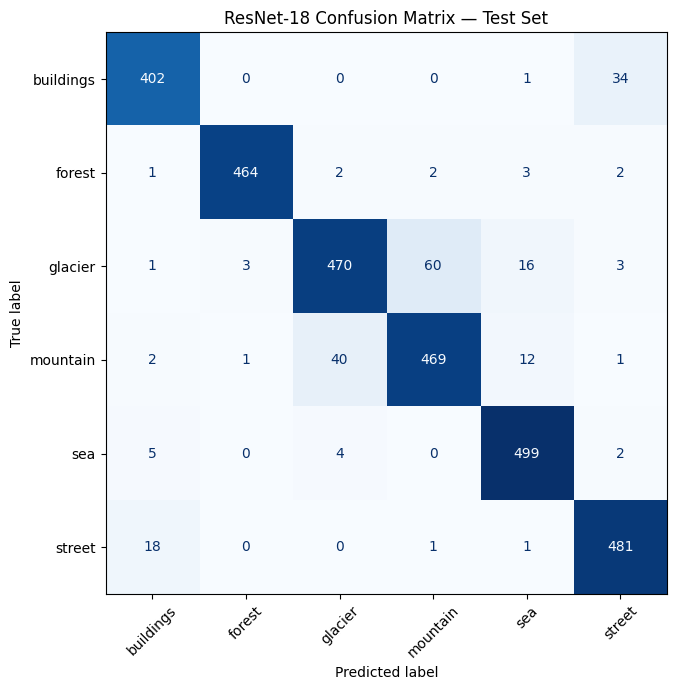

In [25]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(classes)))
)

fig, ax = plt.subplots(figsize=(9, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d",
    colorbar=False
)

plt.title("ResNet-18 Confusion Matrix — Test Set")
plt.tight_layout()
plt.show()

## 21. Per-Class Accuracy (Recall)

**What this cell does:** For each class, the fraction of its true images that were predicted correctly, then sorts them from best to worst. This equals recall.

$$\text{Acc}_c = \frac{\text{diagonal}_c}{\text{row sum}_c}$$

**Hand calculations (sorted order of the displayed table)**

| Rank | Class | Calculation | Accuracy |
|---|---|---|---|
| 1 | forest | $464/474$ | 0.9789 |
| 2 | sea | $499/510$ | 0.9784 |
| 3 | street | $481/501$ | 0.9601 |
| 4 | buildings | $402/437$ | 0.9199 |
| 5 | mountain | $469/525$ | 0.8933 |
| 6 | glacier | $470/553$ | 0.8499 |

Sum of the six values $= 0.9789 + 0.9784 + 0.9601 + 0.9199 + 0.8933 + 0.8499 = 5.5805$, so the **macro-average recall** is $5.5805/6 = 0.9301$ ✔ (matches the *macro avg recall* in Section 19). It differs slightly from overall accuracy ($0.9283$) because overall accuracy weights each class by its size.

In [26]:
class_accuracy = {}

for i, cls in enumerate(classes):
    mask = y_true == i

    class_accuracy[cls] = (
        float((y_pred[mask] == i).mean())
        if mask.sum() > 0 else np.nan
    )

class_accuracy_df = pd.DataFrame({
    "Class": list(class_accuracy.keys()),
    "Test Accuracy": list(class_accuracy.values())
})

display(
    class_accuracy_df.sort_values(
        "Test Accuracy",
        ascending=False
    ).style.format({"Test Accuracy": "{:.4f}"})
)

,Class,Test Accuracy
1,forest,0.9789
4,sea,0.9784
5,street,0.9601
0,buildings,0.9199
3,mountain,0.8933
2,glacier,0.8499


## 22. Inspecting Misclassified Images

**What this cell does:** Finds every wrong prediction and shows the first 12 with their true and predicted labels.

**Outputs recorded:** 215 incorrect predictions out of 3,000.

**Hand calculations**

- Error rate: $\dfrac{215}{3000} = 7.17\,\%$, which equals $1 - 0.9283$ ✔
- Images displayed: $\dfrac{12}{215} = 5.6\,\%$ of errors. This is a qualitative sample (the first 12 by index), **not** a representative sample, so it should be used to generate hypotheses (blur, mixed scenes, snow vs ice), not to measure error causes.

Incorrect predictions: 215
Total test images: 3000


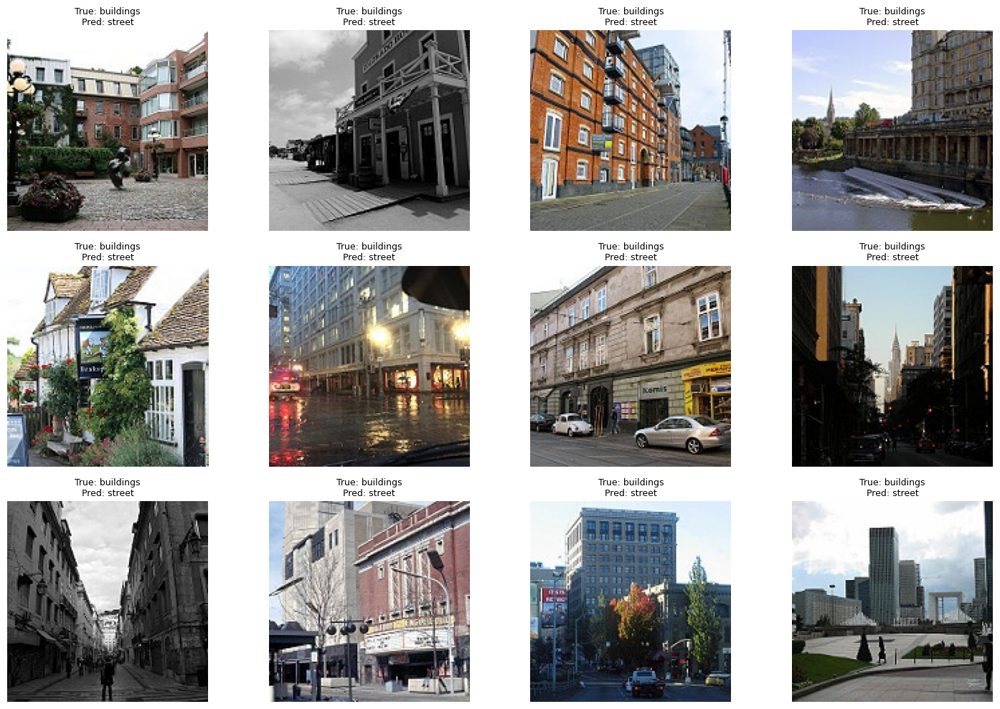

In [27]:
wrong_indices = np.where(y_true != y_pred)[0]

print("Incorrect predictions:", len(wrong_indices))
print("Total test images:", len(y_true))

if len(wrong_indices) > 0:
    selected = wrong_indices[:min(12, len(wrong_indices))]
    n_show = len(selected)

    fig, axes = plt.subplots(3, 4, figsize=(15, 10))
    axes = axes.flatten()

    for ax, idx in zip(axes, selected):
        row = test_part.iloc[idx]

        with Image.open(row["path"]) as img:
            ax.imshow(img.convert("RGB"))

        ax.set_title(
            f"True: {classes[y_true[idx]]}\n"
            f"Pred: {classes[y_pred[idx]]}",
            fontsize=9
        )
        ax.axis("off")

    for ax in axes[n_show:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No incorrect predictions found.")

## 9. Model Explainability with Grad-CAM

Grad-CAM uses gradients and convolutional feature maps to generate a heatmap of image regions associated with a model prediction. These visualizations help inspect model behaviour but do not prove that every highlighted region is causally responsible for the prediction.

## 23. Grad-CAM Implementation

**What this cell does:** Registers a forward hook (saves feature maps $A^k$) and a backward hook (saves gradients) on the last residual block `model.layer4[-1]`, then builds a heatmap for the predicted class.

**Equations**

$$\alpha_k^c = \frac{1}{Z}\sum_{i}\sum_{j}\frac{\partial y^c}{\partial A^k_{ij}}, \qquad L^c_{\text{Grad-CAM}} = \text{ReLU}\!\left(\sum_k \alpha_k^c\,A^k\right)$$

Final map: $\;\hat L = \dfrac{L - L_{\min}}{L_{\max} + 10^{-8}}$ (scaled to $[0,1]$).

**Hand calculations for ResNet-18 at 224 × 224**

- `layer4` output size: $224 / 32 = 7$, so $7 \times 7$ maps with **512** channels.
- $Z = 7 \times 7 = 49$, so each weight $\alpha_k$ is the average of 49 gradients (`mean(dim=(2,3))`).
- 512 weights combine 512 maps into one $7 \times 7$ map; bilinear interpolation upsamples it by $224/7 = 32$ per side to the image size.
- ReLU keeps only evidence that **increases** the class score.

In [28]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None
        self.gradients = None

        self.forward_handle = target_layer.register_forward_hook(
            self._save_activations
        )

        self.backward_handle = target_layer.register_full_backward_hook(
            self._save_gradients
        )

    def _save_activations(self, module, inputs, output):
        self.activations = output.detach()

    def _save_gradients(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate(self, input_tensor, class_idx=None):
        self.model.eval()
        self.model.zero_grad(set_to_none=True)

        output = self.model(input_tensor)

        if class_idx is None:
            class_idx = int(output.argmax(dim=1).item())

        score = output[:, class_idx].sum()
        score.backward()

        weights = self.gradients.mean(
            dim=(2, 3),
            keepdim=True
        )

        cam = (weights * self.activations).sum(dim=1, keepdim=True)
        cam = F.relu(cam)

        cam = F.interpolate(
            cam,
            size=input_tensor.shape[2:],
            mode="bilinear",
            align_corners=False
        )

        cam = cam[0, 0]
        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)

        return cam.detach().cpu().numpy(), class_idx

    def remove_hooks(self):
        self.forward_handle.remove()
        self.backward_handle.remove()

## 24. Grad-CAM Visualisations on 6 Test Images

**What this cell does:** Takes 6 random test images, shows the original, the heatmap overlay and the raw heatmap, and prints the prediction with its softmax confidence, $p_c = e^{z_c} / \sum_j e^{z_j}$. It then removes the hooks.

**Outputs read from the figure**

| # | True | Predicted | Confidence | Correct? | Where the heat is |
|---|---|---|---|---|---|
| 1 | mountain | mountain | 92.64 % | yes | central ridge and slopes |
| 2 | glacier | glacier | 99.98 % | yes | the ice tongue at top centre |
| 3 | mountain | mountain | 81.13 % | yes | the snowy peak |
| 4 | buildings | buildings | 99.85 % | yes | the tower block |
| 5 | street | street | 99.28 % | yes | the alley centre |
| 6 | glacier | **buildings** | **77.75 %** | **no** | **the watermark text strip at the bottom** |

**Hand calculations**

- Accuracy on this sample: $\dfrac{5}{6} = 83.3\,\%$ (only 6 images, so it says nothing about the 92.83 % test accuracy).
- Illustrative softmax (made-up logits $z = [3,\,1,\,0.5,\,0,\,-1,\,-2]$): $\sum e^{z} = 20.09 + 2.72 + 1.65 + 1 + 0.37 + 0.14 = 25.96$, so $p_1 = 20.09/25.96 = 77.4\,\%$, about the same confidence as the wrong prediction in row 6. A confidence near 78 % is not high enough to trust blindly.
- **Important finding:** in row 6 the heat sits on a watermark-like text strip rather than on the mountains. This is a small example of a **shortcut feature** (see Question 6 below). Grad-CAM shows association, not proof of causation.

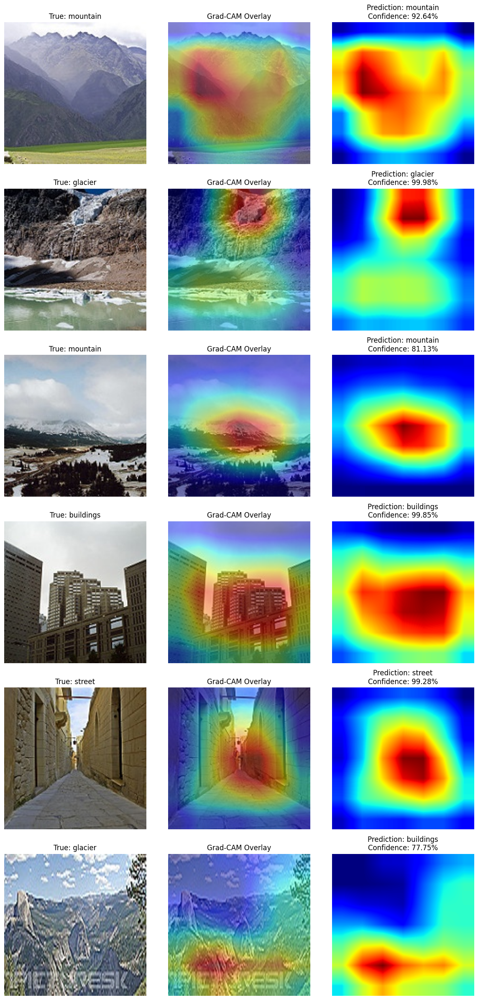

In [29]:
gradcam = GradCAM(model, model.layer4[-1])

n_examples = min(6, len(test_part))
examples = test_part.sample(n_examples, random_state=42)

fig, axes = plt.subplots(
    n_examples, 3,
    figsize=(12, 4 * n_examples)
)

if n_examples == 1:
    axes = np.expand_dims(axes, axis=0)

for row_idx, (_, row) in enumerate(examples.iterrows()):
    with Image.open(row["path"]) as img:
        original = img.convert("RGB").resize((IMG_SIZE, IMG_SIZE))

    input_tensor = eval_transform(original).unsqueeze(0).to(device)

    cam, predicted_idx = gradcam.generate(input_tensor)

    original_array = np.asarray(original)

    with torch.no_grad():
        probabilities = torch.softmax(model(input_tensor), dim=1)[0]
        confidence = float(probabilities[predicted_idx].item())

    axes[row_idx, 0].imshow(original_array)
    axes[row_idx, 0].set_title(f"True: {row['label']}")
    axes[row_idx, 0].axis("off")

    axes[row_idx, 1].imshow(original_array)
    axes[row_idx, 1].imshow(cam, cmap="jet", alpha=0.45)
    axes[row_idx, 1].set_title("Grad-CAM Overlay")
    axes[row_idx, 1].axis("off")

    axes[row_idx, 2].imshow(cam, cmap="jet")
    axes[row_idx, 2].set_title(
        f"Prediction: {classes[predicted_idx]}\n"
        f"Confidence: {confidence:.2%}"
    )
    axes[row_idx, 2].axis("off")

plt.tight_layout()
plt.show()

gradcam.remove_hooks()

## 10. Save the Model and Results

The best model checkpoint, evaluation metrics, and training history are saved to the Kaggle working directory. These outputs can be downloaded from the notebook's Output section after the cells finish running.

## 25. Saving the Model, Metrics and Training History

**What this cell does:** Saves the model weights with the class names and image size, writes the metrics to JSON and the training history to CSV.

**Outputs recorded (JSON):** training 11,928; validation 2,106; testing 3,000; test accuracy 0.92833; macro-F1 0.92959; weighted-F1 0.92799; best validation macro-F1 0.93426.

**Hand checks**

- $\text{test\_accuracy} = \dfrac{2785}{3000} = 0.928333$ ✔
- Rounded JSON values match the printed table: $0.9283,\ 0.9296,\ 0.9280,\ 0.9343$ ✔
- Split sizes add up: $11{,}928 + 2106 + 3000 = 17{,}034$ ✔
- Checkpoint size $\approx 11{,}179{,}590 \times 4\text{ bytes} \approx 44.7$ MB plus small BatchNorm buffers.

In [30]:
import json

MODEL_PATH = "/kaggle/working/intel_resnet18_best.pth"
METRICS_PATH = "/kaggle/working/evaluation_metrics.json"
HISTORY_PATH = "/kaggle/working/training_history.csv"

torch.save({
    "model_state_dict": model.state_dict(),
    "classes": classes,
    "class_to_idx": class_to_idx,
    "img_size": IMG_SIZE,
    "architecture": "ResNet-18"
}, MODEL_PATH)

metrics = {
    "architecture": "ResNet-18",
    "classes": classes,
    "training_images": int(len(train_part)),
    "validation_images": int(len(val_part)),
    "testing_images": int(len(test_part)),
    "test_accuracy": test_accuracy,
    "test_macro_f1": float(test_macro_f1),
    "test_weighted_f1": float(test_weighted_f1),
    "best_validation_macro_f1": float(best_val_f1)
}

with open(METRICS_PATH, "w") as f:
    json.dump(metrics, f, indent=4)

pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)

print("Model saved:", MODEL_PATH)
print("Metrics saved:", METRICS_PATH)
print("Training history saved:", HISTORY_PATH)
print(json.dumps(metrics, indent=4))

Model saved: /kaggle/working/intel_resnet18_best.pth
Metrics saved: /kaggle/working/evaluation_metrics.json
Training history saved: /kaggle/working/training_history.csv
{
    "architecture": "ResNet-18",
    "classes": [
        "buildings",
        "forest",
        "glacier",
        "mountain",
        "sea",
        "street"
    ],
    "training_images": 11928,
    "validation_images": 2106,
    "testing_images": 3000,
    "test_accuracy": 0.9283333333333333,
    "test_macro_f1": 0.9295858000196017,
    "test_weighted_f1": 0.9279870421194782,
    "best_validation_macro_f1": 0.9342556594882382
}


## 26. Summary Table of Scores

**What this cell does:** Collects the four key scores into a table.

| Metric | Score | Source |
|---|---|---|
| Test Accuracy | 0.9283 | $2785/3000$ |
| Test Macro-F1 | 0.9296 | mean of six class F1 |
| Test Weighted-F1 | 0.9280 | support-weighted F1 |
| Best Validation Macro-F1 | 0.9343 | epoch 1 |

**Hand comparison:** the spread of the three test metrics is $0.9296 - 0.9280 = 0.0016$. Validation to test macro-F1 gap $= 0.9343 - 0.9296 = 0.0047$ (about half a percentage point).

In [31]:
summary_df = pd.DataFrame([
    {"Metric": "Test Accuracy", "Score": test_accuracy},
    {"Metric": "Test Macro-F1", "Score": test_macro_f1},
    {"Metric": "Test Weighted-F1", "Score": test_weighted_f1},
    {"Metric": "Best Validation Macro-F1", "Score": best_val_f1}
])

display(summary_df.style.format({"Score": "{:.4f}"}))

,Metric,Score
0,Test Accuracy,0.9283
1,Test Macro-F1,0.9296
2,Test Weighted-F1,0.9280
3,Best Validation Macro-F1,0.9343


## 27. Final Printed Summary

**What this cell does:** Prints architecture, classes, split sizes, test metrics, a 3-decimal classification report and a reminder about duplicate screening.

**Key numbers to quote in the report:** 11,928 / 2,106 / 3,000 images; accuracy $0.9283$; macro-F1 $0.9296$; weighted-F1 $0.9280$; best class forest ($F1 = 0.985$), weakest class glacier ($F1 = 0.879$).

**Honest caveat (from the cell output):** screening covered only 50-200 test and 500-2,500 train images in the near-duplicate pass, so it does not certify the whole dataset. The exact-duplicate (MD5) check did cover all 17,034 files and found 3 cross-split pairs.

In [32]:
print("=" * 55)
print("INTEL IMAGE CLASSIFICATION — FINAL SUMMARY")
print("=" * 55)

print("Architecture: ResNet-18")
print("Classes:", ", ".join(classes))
print("Training images:", len(train_part))
print("Validation images:", len(val_part))
print("Test images:", len(test_part))

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Macro-F1: {test_macro_f1:.4f}")
print(f"Test Weighted-F1: {test_weighted_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(classes))),
    target_names=classes,
    digits=3,
    zero_division=0
))

print("\nDuplicate-screening note:")
print(
    "Exact duplicate checking and near-duplicate screening should be "
    "reported according to the number of images actually checked. "
    "Sampled checks do not prove the complete dataset is duplicate-free."
)

INTEL IMAGE CLASSIFICATION — FINAL SUMMARY
Architecture: ResNet-18
Classes: buildings, forest, glacier, mountain, sea, street
Training images: 11928
Validation images: 2106
Test images: 3000
Test Accuracy: 0.9283
Test Macro-F1: 0.9296
Test Weighted-F1: 0.9280

Classification Report:
              precision    recall  f1-score   support

   buildings      0.937     0.920     0.928       437
      forest      0.991     0.979     0.985       474
     glacier      0.911     0.850     0.879       553
    mountain      0.882     0.893     0.887       525
         sea      0.938     0.978     0.958       510
      street      0.920     0.960     0.939       501

    accuracy                          0.928      3000
   macro avg      0.930     0.930     0.930      3000
weighted avg      0.928     0.928     0.928      3000


Duplicate-screening note:
Exact duplicate checking and near-duplicate screening should be reported according to the number of images actually checked. Sampled checks do not

## 11. Conclusion

This project applies transfer learning using ResNet-18 to classify six scene categories in the Intel Image Classification dataset: buildings, forest, glacier, mountain, sea, and street. Images are resized and normalized, while data augmentation is applied during training.

The model is selected using validation macro-F1 and evaluated on the separate test set. Performance is assessed through test accuracy, macro-F1, weighted-F1, a classification report, and a confusion matrix. Grad-CAM visualizations are generated to inspect image regions associated with model predictions.

The final report should include the actual metrics produced by the experiment. Duplicate screening results should be described according to the images checked, and sampled checks should not be presented as a complete dataset audit.

### Actual Results to Cite in the Conclusion

| Item | Value |
|---|---|
| Train / validation / test images | 11,928 / 2,106 / 3,000 |
| Epochs run (early stop) | 3 of 5, best = epoch 1 |
| Best validation macro-F1 | 0.9343 |
| Test accuracy | 0.9283 (2785 / 3000) |
| Test macro-F1 | 0.9296 |
| Test weighted-F1 | 0.9280 |
| Strongest / weakest class (F1) | forest 0.985 / glacier 0.879 |
| Main confusion | glacier $\leftrightarrow$ mountain (60 + 40 = 100 errors) |
| Exact duplicates | 18 groups, 3 across train/test (0.10 % of test) |

# Final Answers: Short Questions with Working

## 1. Why does a random split of chest X-rays overestimate performance?

Chest X-ray datasets contain **several images per patient** (for example ChestX-ray14 has about 112,000 images from about 31,000 patients, roughly 3.6 each). A random *image-level* split puts some images of a patient in training and others in test. This is **data leakage**:

- The model can memorise patient-specific cues (anatomy, implants, scars, tubes, scanner, positioning) and recognise the same patient in the test set. It is rewarded for **identity**, not for the disease.
- The images of one patient are highly correlated, so test samples are not independent of training samples and the estimated error is too optimistic.

**Working (illustration, a patient with $m = 4$ images, 80 / 20 random split):** probability that a given test image has at least one sibling in training:

$$P = 1 - 0.2^{\,m-1} = 1 - 0.2^{3} = 1 - 0.008 = 0.992 \approx 99\,\%$$

So almost every test image has a "sibling" in training. **Fix:** split by **patient** (group split, for example `StratifiedGroupKFold` with patient ID as the group), preferably also validating on a different hospital. In this notebook, the Intel filenames have no patient ID (`GROUP_PATTERN = None`, 1.00 image per group), and 3 exact train/test duplicates were found, a small version of the same leakage risk.

## 2. Class weights for 900 and 100 training images, using $w_c = \dfrac{N}{K \times n_c}$

$N = 900 + 100 = 1000$ and $K = 2$.

$$w_{900} = \frac{1000}{2 \times 900} = \frac{1000}{1800} = 0.556$$

$$w_{100} = \frac{1000}{2 \times 100} = \frac{1000}{200} = 5.0$$

**Check:** the rare class gets $5.0 / 0.556 = 9$ times the weight (equal to the 900 : 100 ratio). Total weight per class: $900 \times 0.556 = 500$ and $100 \times 5.0 = 500$, so each class contributes equally to the loss.

## 3. Focal loss with $\gamma = 2$: down-weighting at $p_t = 0.8$

$$FL(p_t) = -(1 - p_t)^{\gamma}\,\log(p_t)$$

The modulating factor is $(1 - p_t)^{\gamma} = (1 - 0.8)^2 = 0.2^2 = 0.04$.

**Down-weighting factor** $= \dfrac{1}{0.04} = 25$, so an easy example with $p_t = 0.8$ is down-weighted by a factor of **25** (it keeps only 4 % of its cross-entropy loss).

**Numerical check:** $CE = -\ln 0.8 = 0.2231$; $FL = 0.04 \times 0.2231 = 0.00893$ and $0.2231 / 0.00893 = 25$ ✔. (No $\alpha$ balancing term is applied here.)

## 4. PPV with sensitivity 0.90, specificity 0.95, prevalence 2 %

$$PPV = \frac{\text{Sens} \times \text{Prev}}{\text{Sens} \times \text{Prev} + (1 - \text{Spec})(1 - \text{Prev})}$$

$$PPV = \frac{0.90 \times 0.02}{0.90 \times 0.02 + 0.05 \times 0.98} = \frac{0.018}{0.018 + 0.049} = \frac{0.018}{0.067} = 0.269$$

**Check with 100,000 people:** diseased $= 2000$, so $TP = 0.90 \times 2000 = 1800$ and $FN = 200$. Healthy $= 98{,}000$, so $FP = 0.05 \times 98{,}000 = 4900$ and $TN = 93{,}100$.

$$PPV = \frac{1800}{1800 + 4900} = \frac{1800}{6700} = 26.9\,\%$$

**PPV $\approx 26.9\,\%$**: only about 1 in 4 positive results is a true case, because the disease is rare. (For reference, $NPV = 93{,}100 / 93{,}300 = 99.8\,\%$.)

## 5. When is macro-F1 a better selection metric than weighted F1?

- **Macro-F1** averages the F1 of each class equally: $\frac{1}{K}\sum_c F1_c$. **Weighted F1** weights by class size: $\sum_c \frac{n_c}{N} F1_c$.
- Macro-F1 is better when **classes are imbalanced and the rare classes matter as much as the common ones** (for example a rare pathology), because weighted F1 is dominated by the majority class and can hide a failure on the minority class.
- If classes are roughly balanced the two agree. In this notebook $0.9296$ (macro) vs $0.9280$ (weighted) differ by only $0.0016$, which is why macro-F1 was a safe choice for model selection, and it also does not reward ignoring small classes.

**Working (95 / 5 example):** majority-class $F1 = 0.98$, minority-class $F1 = 0.50$:

$$\text{Weighted} = 0.95(0.98) + 0.05(0.50) = 0.931 + 0.025 = 0.956$$

$$\text{Macro} = \frac{0.98 + 0.50}{2} = 0.740$$

Weighted F1 looks excellent (0.956) even though the minority class is handled poorly; macro-F1 (0.740) exposes it. Weighted F1 is preferable only when the test class mix matches deployment and overall volume is what matters.

## 6. Grad-CAM highlights a hospital label in the corner of X-rays. What next?

This is **shortcut learning** (a spurious or confounding feature): the model uses the marker, which is correlated with the label (for example one hospital sees more sick patients), instead of the lung findings. Its good accuracy is therefore not trustworthy. Steps:

1. **Do not deploy or report the score as real performance.** Treat the result as unreliable.
2. **Confirm the shortcut.** Look at many images, not one. Run a counterfactual test: mask or crop the corner and re-evaluate. A large accuracy drop, or a changed prediction, confirms dependence.
3. **Audit the data.** Cross-tabulate label against hospital, scanner and marker (e.g. sick rate per hospital). If the rates differ a lot, the confound is built into the data.
4. **Fix it.** Crop or inpaint the text and markers, standardise images across sites, add augmentations such as random crops and cut-out so corners cannot be relied on, and rebalance across hospitals.
5. **Retrain with a leakage-proof split** (split by patient and by hospital), then validate on an **external hospital** not seen in training.
6. **Re-run Grad-CAM and re-check metrics.** Heat should move onto the lungs and the score may drop; the lower number is the honest one. Remember Grad-CAM shows association, not proof of cause.
7. **Document** the finding and the mitigation.

**Link to this notebook:** the sixth Grad-CAM example (Section 24) put its heat on a watermark text strip and gave a wrong prediction (glacier called buildings, 77.75 % confidence), a small-scale version of the same problem.